In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [5]:
# Путь зависит от того, откуда VS Code запускает ноутбук.
paths = [
    Path("../data/players.csv"),
    Path("data/players.csv")
]

DATA_PATH = next(
    (path for path in paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "players.csv не найден. Проверь папку data и название файла."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print("Файл:", DATA_PATH.resolve())
print("Размер датасета:", df.shape)

display(df.head())

Файл: /Users/mdnv/Desktop/ML/ML players-eda-pw-4/data/players.csv
Размер датасета: (19789, 60)


,player_id,common_name,first_name,last_name,overall_rating,position,alternate_positions,club,league,nationality,gender,preferred_foot,skill_moves,weak_foot,height_cm,weight_kg,birthdate,playstyles,pace,shooting,passing,dribbling,defending,physicality,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,edition,snapshot_date
0,227203,Alexia Putellas,Alexia,Putellas Segura,91,CM,CAM ST,London City,Barclays WSL,Spain,Women's Football,Left,5,5,NaN,NaN,1994-02-04,"Finesse Shot, Gamechanger, Tiki Taka, Inventiv...",80,90,91,92,72,75,88,90,74,94,87,91,89,83,90,94,80,80,87,92,92,89,82,80,74,90,70,78,91,93,89,92,60,82,64,15,17,11,15,10,fc27,2026-09-12
1,231747,NaN,Kylian,Mbappé,91,ST,LW,Real Madrid,LALIGA EA SPORTS,France,Men's Football,Right,5,4,NaN,NaN,1998-12-20,"Finesse Shot, Acrobatic, Low Driven Shot, Game...",96,91,80,92,29,76,74,95,78,87,87,92,80,70,74,93,97,96,93,92,82,91,90,83,77,86,61,19,91,83,86,88,15,34,24,13,5,7,11,6,fc27,2026-09-12
2,239085,NaN,Erling,Haaland,91,ST,NaN,Manchester City,Premier League,Norway,Men's Football,Left,3,3,NaN,NaN,2000-07-21,"Chip Shot, Power Shot, Precision Header, Acrob...",87,92,71,80,47,89,58,96,85,78,90,79,77,62,66,83,81,92,66,94,69,94,93,80,93,83,88,43,95,75,89,86,42,47,33,7,14,13,11,7,fc27,2026-09-12
3,192119,NaN,Thibaut,Courtois,90,GK,NaN,Real Madrid,LALIGA EA SPORTS,Belgium,Men's Football,Left,1,3,NaN,NaN,1992-05-11,"Far Throw, Far Reach, Rush Out+",87,89,78,90,46,90,14,14,13,33,12,13,19,20,35,23,42,52,63,88,45,59,68,38,70,17,23,15,13,60,27,66,20,18,16,87,89,78,90,90,fc27,2026-09-12
4,202126,NaN,Harry,Kane,90,ST,NaN,FC Bayern München,Bundesliga,England,Men's Football,Right,3,4,NaN,NaN,1993-07-28,"Precision Header, Low Driven Shot, Gamechanger...",62,94,83,82,49,83,80,96,89,86,91,80,82,69,82,87,63,62,67,94,72,92,87,76,87,91,82,42,96,86,93,92,46,44,42,8,10,11,14,11,fc27,2026-09-12


# ПР-4. Сравнение наборов признаков для линейной регрессии

Цель работы — предсказать общий рейтинг игрока overall_rating
и сравнить модель на полном и сокращённом наборах числовых признаков.

Целевая переменная измеряется в баллах рейтинга.

player_id исключается из признаков, поскольку является идентификатором
игрока, а не количественной характеристикой его способностей.

Для предобработки используется аналог пайплайна ПР-3:
ColumnTransformer, заполнение пропусков медианой и StandardScaler.

Категориальные признаки в данном сравнении не используются:
по заданию базовая модель обучается на числовых признаках.

In [6]:
TARGET = "overall_rating"

# Пропуски целевой переменной не заполняем.
df = df.dropna(subset=[TARGET]).copy()

# Проверяем, что один игрок не представлен несколькими строками.
# Для проверенного исходного players.csv повторов нет.
assert df["player_id"].is_unique, (
    "В файле есть повторяющиеся player_id. "
    "Нужно разделять данные по игрокам, а не по отдельным строкам."
)

y = df[TARGET]

# Берём числовые столбцы, исключая цель и идентификатор.
X = (
    df.select_dtypes(include="number")
    .drop(columns=[TARGET, "player_id"])
    .replace([np.inf, -np.inf], np.nan)
)

# Откладываем test.
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Оставшуюся часть делим на train и validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# Определяем непригодные столбцы только по train.
empty_cols = X_train.columns[
    X_train.isna().all()
].tolist()

all_features = [
    col for col in X_train.columns
    if col not in empty_cols
]

print("\nПолностью пустые признаки:", empty_cols)
print("Число доступных числовых признаков:", len(all_features))

display(
    X_train[all_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .rename("Число пропусков")
    .to_frame()
)

Train: (11873, 44)
Validation: (3958, 44)
Test: (3958, 44)

Полностью пустые признаки: ['height_cm', 'weight_kg']
Число доступных числовых признаков: 42


,Число пропусков
skill_moves,0
mentality_vision,0
power_shot_power,0
power_jumping,0
power_stamina,0
power_strength,0
power_long_shots,0
mentality_aggression,0
mentality_interceptions,0
mentality_positioning,0


Столбцы height_cm и weight_kg полностью пусты в обучающей выборке.
Для них невозможно вычислить медиану, поэтому они исключены из обеих моделей.

Для остальных числовых признаков используется заполнение медианой:
она менее чувствительна к крайним значениям, чем среднее.
Если в столбце нет пропусков, заполнение не меняет его значения.

Разбиение данных выполнено до расчёта медиан, параметров масштабирования
и корреляций.

In [7]:
def make_model(features):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, features)
    ], remainder="drop")

    return Pipeline([
        ("preprocess", preprocessor),
        ("regression", LinearRegression())
    ])


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


baseline_model = make_model(all_features)
baseline_model.fit(X_train, y_train)

baseline_val_pred = baseline_model.predict(X_val)

print("Базовая модель обучена.")
print("Число признаков:", len(all_features))

display(
    pd.DataFrame(
        [regression_metrics(y_val, baseline_val_pred)],
        index=["Полный набор — validation"]
    ).round(4)
)

Базовая модель обучена.
Число признаков: 42


,MAE,RMSE,R2
Полный набор — validation,1.5541,2.0022,0.9181


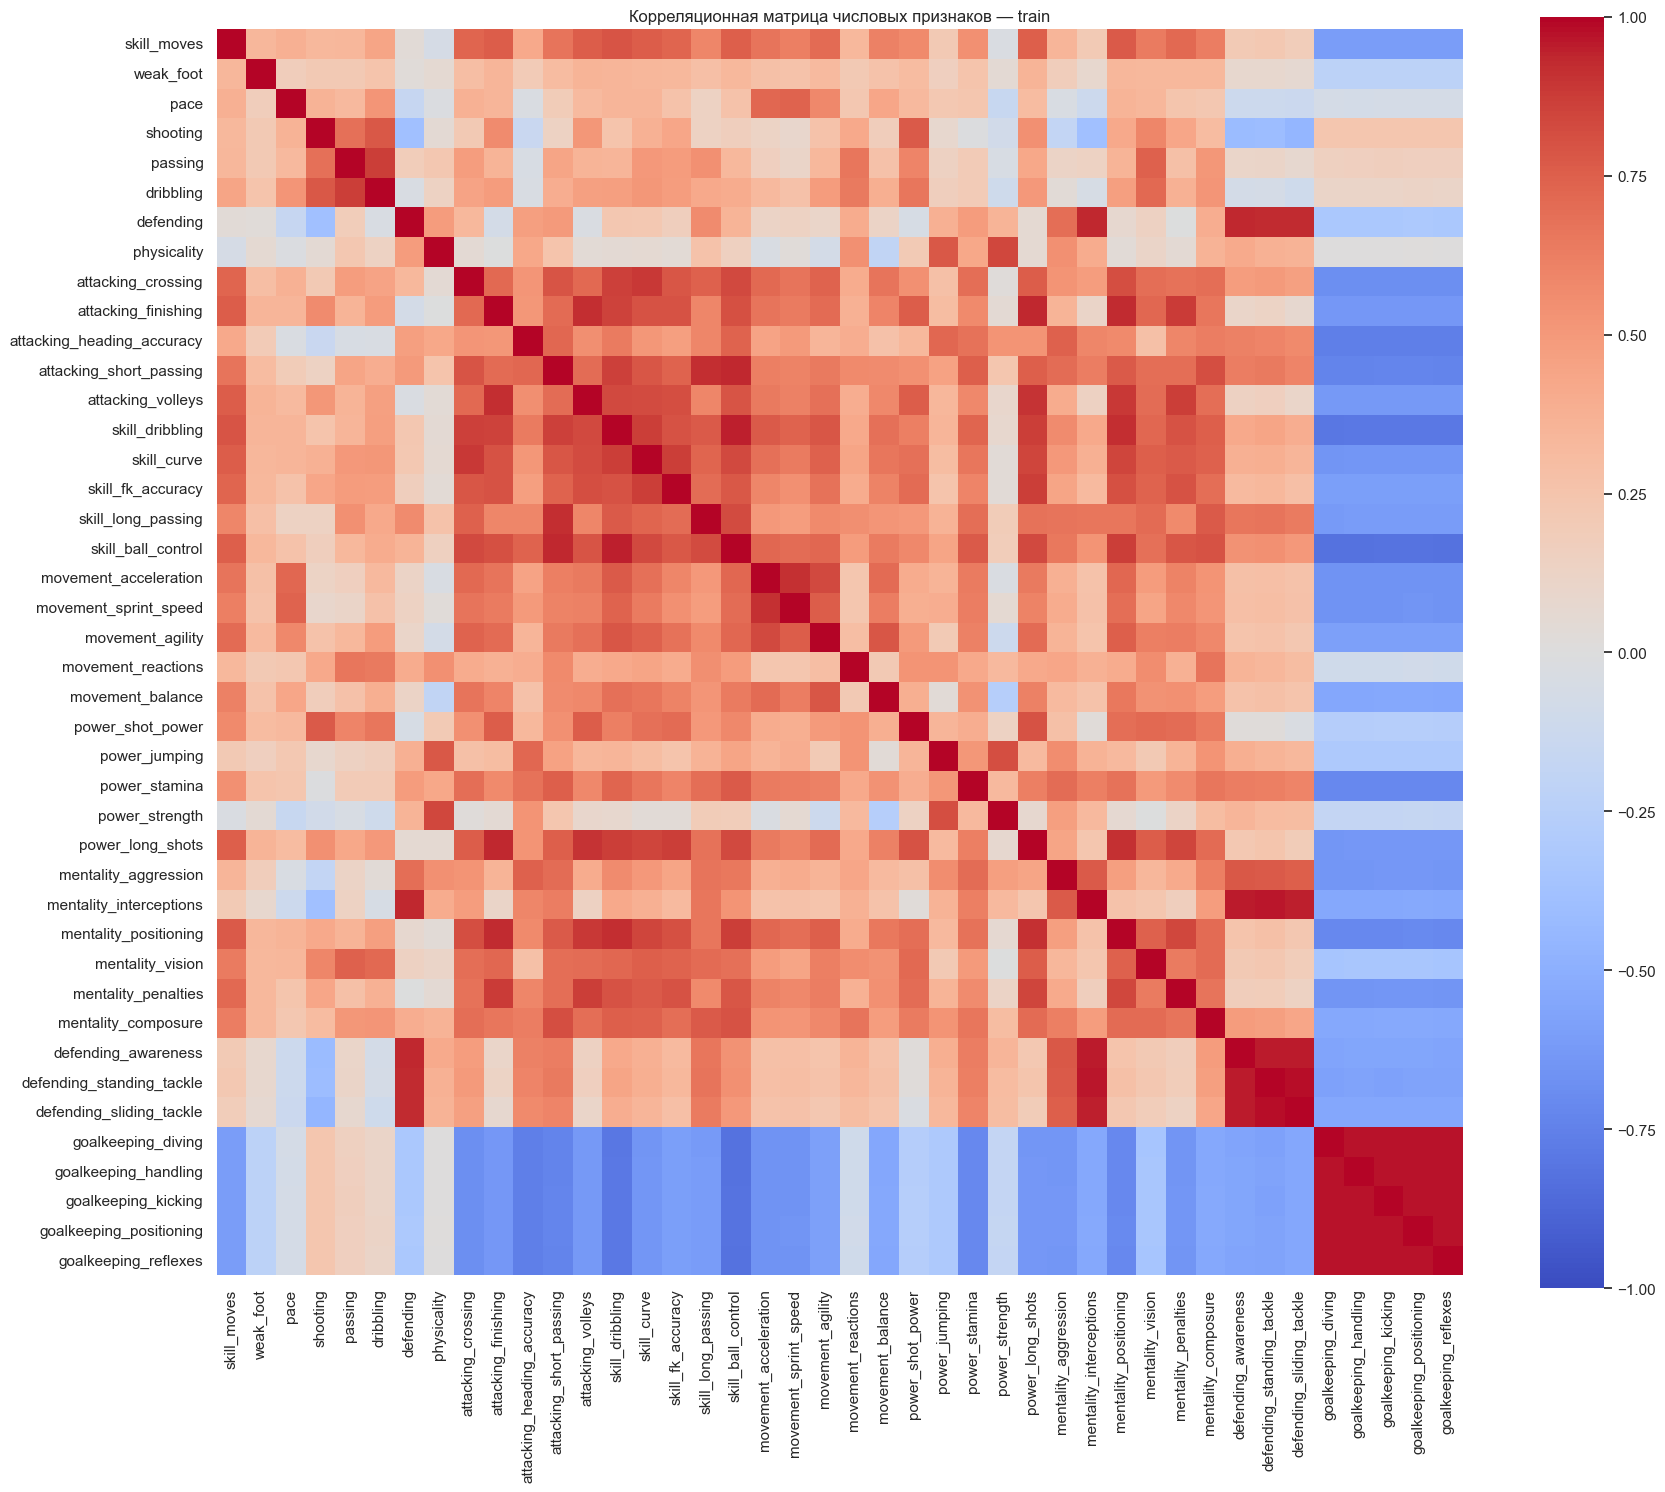

,Признак 1,Признак 2,Корреляция
19,defending_standing_tackle,defending_sliding_tackle,0.977
23,goalkeeping_diving,goalkeeping_reflexes,0.974
29,goalkeeping_positioning,goalkeeping_reflexes,0.973
20,goalkeeping_diving,goalkeeping_handling,0.973
26,goalkeeping_handling,goalkeeping_reflexes,0.973
22,goalkeeping_diving,goalkeeping_positioning,0.972
25,goalkeeping_handling,goalkeeping_positioning,0.972
28,goalkeeping_kicking,goalkeeping_reflexes,0.971
21,goalkeeping_diving,goalkeeping_kicking,0.971
24,goalkeeping_handling,goalkeeping_kicking,0.970


In [8]:
# Корреляции считаем только на train.
# pandas использует доступные пары значений при наличии пропусков.
corr = X_train[all_features].corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False
)

plt.title("Корреляционная матрица числовых признаков — train")
plt.tight_layout()
plt.show()

# Выводим пары с сильной корреляцией.
strong_pairs = []

for i, first in enumerate(all_features):
    for second in all_features[i + 1:]:
        value = corr.loc[first, second]

        if pd.notna(value) and abs(value) > 0.90:
            strong_pairs.append({
                "Признак 1": first,
                "Признак 2": second,
                "Корреляция": value
            })

strong_pairs_df = pd.DataFrame(
    strong_pairs,
    columns=["Признак 1", "Признак 2", "Корреляция"]
)

if not strong_pairs_df.empty:
    strong_pairs_df = (
        strong_pairs_df
        .assign(
            abs_corr=lambda table: table["Корреляция"].abs()
        )
        .sort_values("abs_corr", ascending=False)
        .drop(columns="abs_corr")
    )

display(strong_pairs_df.round(3))

In [9]:
THRESHOLD = 0.90

reduced_features = []
removed_features = []

for feature in all_features:
    correlated_with = [
        kept
        for kept in reduced_features
        if abs(corr.loc[feature, kept]) > THRESHOLD
    ]

    if correlated_with:
        kept_feature = correlated_with[0]

        removed_features.append({
            "Удалённый признак": feature,
            "Сохранённый связанный признак": kept_feature,
            "|r|": abs(corr.loc[feature, kept_feature])
        })
    else:
        reduced_features.append(feature)

print("Полный набор:", len(all_features))
print("Сокращённый набор:", len(reduced_features))
print("Удалено:", len(removed_features))

display(
    pd.DataFrame(
        removed_features,
        columns=[
            "Удалённый признак",
            "Сохранённый связанный признак",
            "|r|"
        ]
    ).round(3)
)

print("\nСохранённые признаки:")
print(reduced_features)

reduced_model = make_model(reduced_features)
reduced_model.fit(X_train, y_train)

reduced_val_pred = reduced_model.predict(X_val)

validation_results = pd.DataFrame({
    "Полный набор": regression_metrics(
        y_val, baseline_val_pred
    ),
    "Сокращённый набор": regression_metrics(
        y_val, reduced_val_pred
    )
}).T

validation_results["Число признаков"] = [
    len(all_features),
    len(reduced_features)
]

display(validation_results.round(4))

Полный набор: 42
Сокращённый набор: 28
Удалено: 14


,Удалённый признак,Сохранённый связанный признак,|r|
0,attacking_volleys,attacking_finishing,0.918
1,skill_long_passing,attacking_short_passing,0.915
2,skill_ball_control,attacking_short_passing,0.932
3,movement_sprint_speed,movement_acceleration,0.912
4,power_long_shots,attacking_finishing,0.931
5,mentality_interceptions,defending,0.937
6,mentality_positioning,attacking_finishing,0.924
7,defending_awareness,defending,0.934
8,defending_standing_tackle,defending,0.929
9,defending_sliding_tackle,defending,0.929



Сохранённые признаки:
['skill_moves', 'weak_foot', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physicality', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'movement_acceleration', 'movement_agility', 'movement_reactions', 'movement_balance', 'power_shot_power', 'power_jumping', 'power_stamina', 'power_strength', 'mentality_aggression', 'mentality_vision', 'mentality_penalties', 'mentality_composure', 'goalkeeping_diving']


,MAE,RMSE,R2,Число признаков
Полный набор,1.5541,2.0022,0.9181,42
Сокращённый набор,1.5972,2.0515,0.9140,28


In [10]:
TOLERANCE = 0.02

mae_change = (
    validation_results.loc["Сокращённый набор", "MAE"]
    / validation_results.loc["Полный набор", "MAE"]
    - 1
)

rmse_change = (
    validation_results.loc["Сокращённый набор", "RMSE"]
    / validation_results.loc["Полный набор", "RMSE"]
    - 1
)

use_reduced = (
    mae_change <= TOLERANCE
    and rmse_change <= TOLERANCE
)

if use_reduced:
    final_name = "Сокращённый набор"
    final_features = reduced_features
else:
    final_name = "Полный набор"
    final_features = all_features

print(f"Изменение MAE: {mae_change:+.2%}")
print(f"Изменение RMSE: {rmse_change:+.2%}")
print("Выбран:", final_name)
print("Число признаков:", len(final_features))

Изменение MAE: +2.77%
Изменение RMSE: +2.46%
Выбран: Полный набор
Число признаков: 42


In [11]:
baseline_final = make_model(all_features)
reduced_final = make_model(reduced_features)

# После выбора набора можно обучаться на train + validation.
baseline_final.fit(X_dev, y_dev)
reduced_final.fit(X_dev, y_dev)

test_predictions = {
    "Полный набор": baseline_final.predict(X_test),
    "Сокращённый набор": reduced_final.predict(X_test)
}

test_results = pd.DataFrame({
    name: regression_metrics(y_test, prediction)
    for name, prediction in test_predictions.items()
}).T

test_results["Число признаков"] = [
    len(all_features),
    len(reduced_features)
]

display(test_results.round(4))

final_model = (
    reduced_final if use_reduced else baseline_final
)

final_pred = test_predictions[final_name]

# Проверяем размерности после предобработки.
train_transformed = (
    final_model.named_steps["preprocess"].transform(X_dev)
)

test_transformed = (
    final_model.named_steps["preprocess"].transform(X_test)
)

print("Обучающая часть после преобразования:",
      train_transformed.shape)
print("Test после преобразования:",
      test_transformed.shape)

assert train_transformed.shape[1] == test_transformed.shape[1]

print("\nИтоговая модель:", final_name)

final_metrics = regression_metrics(y_test, final_pred)

print(
    f"MAE = {final_metrics['MAE']:.3f}: "
    "средняя абсолютная ошибка в баллах рейтинга."
)

print(
    f"RMSE = {final_metrics['RMSE']:.3f}: "
    "корень из средней квадратичной ошибки, "
    "также в баллах рейтинга; сильнее учитывает крупные ошибки."
)

print(
    f"R² = {final_metrics['R2']:.3f}: "
    "безразмерный показатель качества относительно "
    "предсказания среднего тестового рейтинга."
)

,MAE,RMSE,R2,Число признаков
Полный набор,1.5190,1.9384,0.9181,42
Сокращённый набор,1.5667,1.9844,0.9141,28


Обучающая часть после преобразования: (15831, 42)
Test после преобразования: (3958, 42)

Итоговая модель: Полный набор
MAE = 1.519: средняя абсолютная ошибка в баллах рейтинга.
RMSE = 1.938: корень из средней квадратичной ошибки, также в баллах рейтинга; сильнее учитывает крупные ошибки.
R² = 0.918: безразмерный показатель качества относительно предсказания среднего тестового рейтинга.


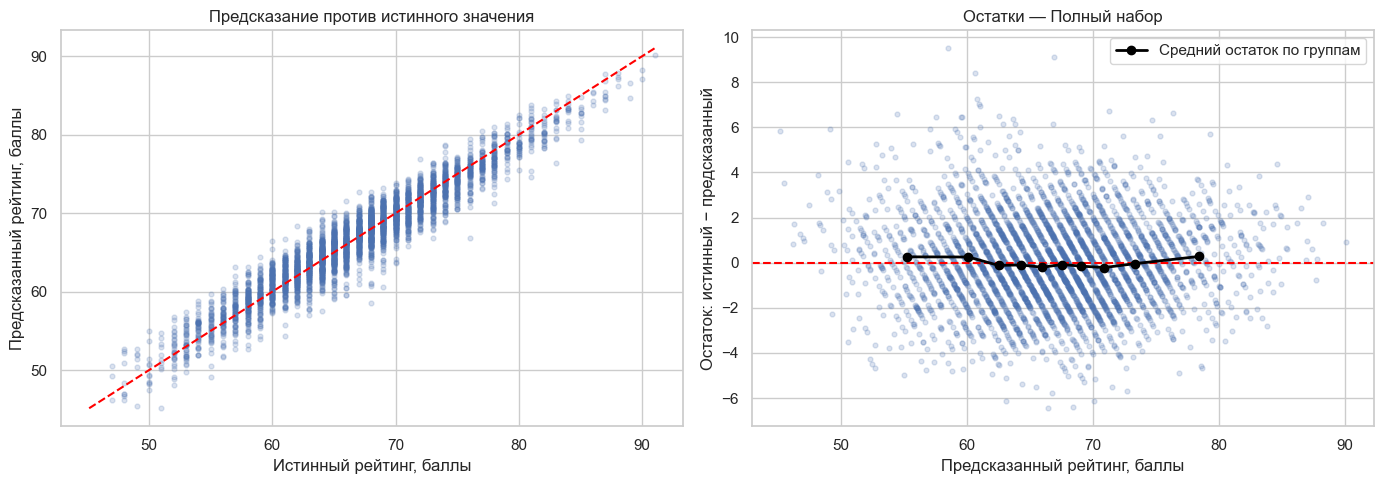

In [12]:
residuals = y_test.to_numpy() - final_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Истинное значение и предсказание.
axes[0].scatter(
    y_test,
    final_pred,
    alpha=0.20,
    s=12
)

lower = min(y_test.min(), final_pred.min())
upper = max(y_test.max(), final_pred.max())

axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Истинный рейтинг, баллы")
axes[0].set_ylabel("Предсказанный рейтинг, баллы")
axes[0].set_title("Предсказание против истинного значения")

# Остатки.
axes[1].scatter(
    final_pred,
    residuals,
    alpha=0.20,
    s=12
)

axes[1].axhline(
    0,
    color="red",
    linestyle="--"
)

# Средний остаток по группам предсказаний.
# Это только диагностика, модель по test не дообучается.
diagnostics = pd.DataFrame({
    "prediction": final_pred,
    "residual": residuals
})

diagnostics["bin"] = pd.qcut(
    diagnostics["prediction"],
    q=10,
    duplicates="drop"
)

mean_residuals = (
    diagnostics
    .groupby("bin", observed=True)[["prediction", "residual"]]
    .mean()
)

axes[1].plot(
    mean_residuals["prediction"],
    mean_residuals["residual"],
    color="black",
    marker="o",
    linewidth=2,
    label="Средний остаток по группам"
)

axes[1].set_xlabel("Предсказанный рейтинг, баллы")
axes[1].set_ylabel("Остаток: истинный − предсказанный")
axes[1].set_title(f"Остатки — {final_name}")
axes[1].legend()

plt.tight_layout()
plt.show()

## Вывод

В работе сравнены две модели линейной регрессии:
на полном наборе из 42 числовых признаков и на сокращённом наборе
из 28 признаков.

Целевой переменной выбран overall_rating. Идентификатор player_id
исключён, а полностью пустые столбцы height_cm и weight_kg
не использованы в моделях.

Для предобработки применён аналог пайплайна ПР-3:
ColumnTransformer с заполнением пропусков медианой и StandardScaler.
Параметры предобработки обучались только на обучающей части данных.

Корреляционная матрица рассчитана на train.
При сокращении набора удалены 14 признаков, имеющих абсолютную
корреляцию выше 0.90 с уже сохранёнными признаками.
Этот подход уменьшает парную избыточность, но не гарантирует
полного устранения мультиколлинеарности.

На validation сокращение признаков увеличило MAE примерно на 2.77%,
а RMSE — на 2.46%. Обе величины превысили заранее установленный
допуск 2%, поэтому финально выбран полный набор из 42 признаков.

После выбора модели она переобучена на объединённых train и validation.
На test получены MAE ≈ 1.52 балла рейтинга и RMSE ≈ 1.94 балла.
Таким образом, средняя абсолютная ошибка прогноза составляет
примерно полтора балла рейтинга.

R² на тестовой выборке составляет примерно 0.918.
Этот показатель характеризует объяснённую вариацию рейтинга
и не является процентом точности.

Сокращённая модель проще, однако при выбранном правиле отбора
она показала несколько большие ошибки. Поэтому для данной работы
сохранён полный набор признаков.